# 06 · Двухэтапные рекомендации с CatBoost

Простое смешивание списков не улучшило качество. Теперь разделяю задачу: сначала собираю небольшой набор кандидатов, затем упорядочиваю их отдельной моделью.

Беру по 30 объектов от Popularity, ItemKNN, ALS и Content, убираю пересечения. CatBoost получает позиции кандидата в этих списках, ALS score, популярность за всю историю и последнюю неделю, активность пользователя и несколько свойств контента. Цель — PairLogit; одна группа соответствует пользователю в конкретном временном окне.

Для обучения использую просмотры 2–8 августа, а кандидатов и признаки считаю по истории до 2 августа. На 9–15 августа выбираю параметры. После этого переобучаю ранкер на обоих прошлых окнах и оцениваю 16–22 августа. Если нужный объект не попал в кандидаты, ранкер уже не сможет его рекомендовать.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA_DIR = Path(os.environ.get("KION_DATA_DIR", ROOT / "data"))
REPORTS = ROOT / "reports" / "full"
K = 10
blas_limit = threadpool_limits(limits=1, user_api="blas")
plt.rcParams.update(
    {
        "figure.figsize": (9, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

## Доступность целевых объектов для ранкера

,split,rows,users,candidate_recall,mean_candidates
0,validation,7334189,103258,0.4183,71.0278
1,rank_train,7058879,100555,0.4357,70.1992
2,test,7645234,106819,0.3977,71.5719


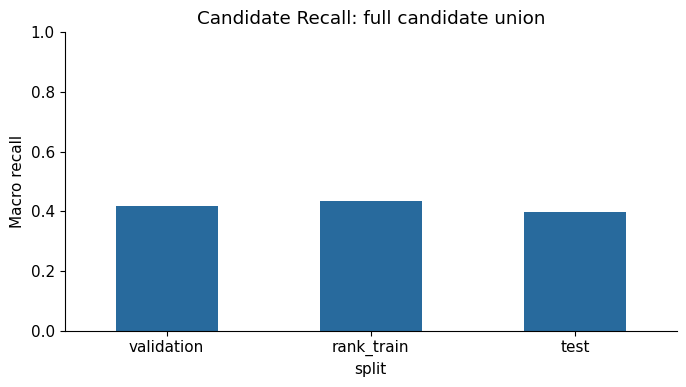

In [2]:
retrieval = pd.read_csv(REPORTS / "candidate_recall.csv")
retrieval["mean_candidates"] = retrieval["rows"] / retrieval["users"]
display(retrieval.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
retrieval.set_index("split")["candidate_recall"].plot.bar(ax=ax, rot=0, color="#286a9d")
ax.set(
    title="Candidate Recall: full candidate union", ylabel="Macro recall", ylim=(0, 1)
)
plt.tight_layout()
plt.show()

## Подбор и итоговая оценка

In [3]:
grid = pd.read_csv(REPORTS / "validation_grid.csv")
display(
    grid.loc[
        grid.model.eq("CatBoost"),
        ["params", "MAP@10", "Recall@10", "NDCG@10", "Coverage"],
    ]
)
metrics = pd.read_csv(REPORTS / "metrics.csv")
display(
    metrics.query("model in ['Hybrid', 'CatBoost']").drop(columns="seconds").round(4)
)

,params,MAP@10,Recall@10,NDCG@10,Coverage
12,"{""iterations"": 100, ""depth"": 4}",0.158851,0.296826,0.205708,0.134867
13,"{""iterations"": 150, ""depth"": 6}",0.160531,0.297964,0.207403,0.133033


,model,split,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage,Users
5,Hybrid,validation,0.1171,0.2473,0.1592,0.3321,0.2343,103258
6,CatBoost,validation,0.1605,0.2980,0.2074,0.3957,0.1330,103258
12,Hybrid,test,0.1056,0.2304,0.1460,0.3154,0.2385,106819
13,CatBoost,test,0.1456,0.2832,0.1920,0.3814,0.1438,106819


## Признаки

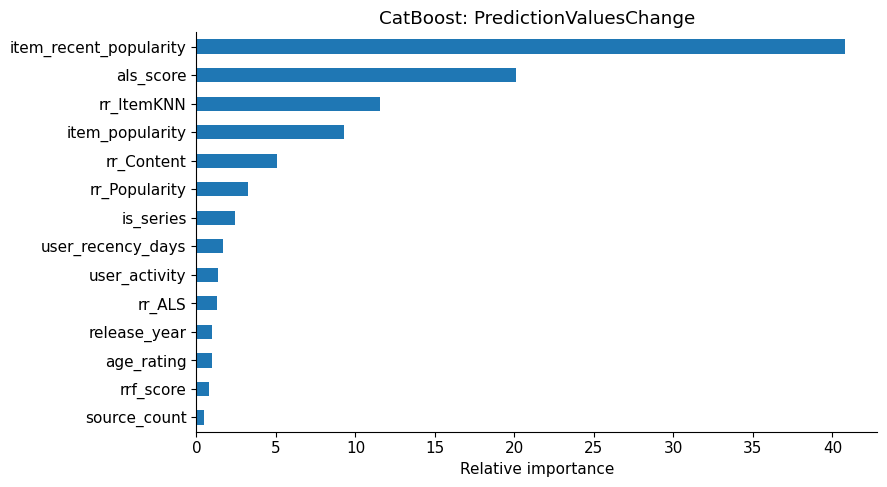

Final training queries: 112347
Final training candidates: 7830078


In [4]:
importance = pd.read_csv(REPORTS / "feature_importance.csv")
fig, ax = plt.subplots(figsize=(9, 5))
importance.sort_values("importance").plot.barh(
    x="feature", y="importance", ax=ax, legend=False
)
ax.set(
    title="CatBoost: PredictionValuesChange", xlabel="Relative importance", ylabel=""
)
plt.tight_layout()
plt.show()
run = json.loads((REPORTS / "run.json").read_text())
print("Final training queries:", run["ranker_training_queries"])
print("Final training candidates:", run["ranker_training_rows"])

## Выводы

CatBoost улучшил результат: Test MAP@10 — **0.1456**, Recall@10 — **0.2832**. Среди исходных семи подходов он оказался первым и на Validation, и на Test.

В тестовый пул кандидатов попало в среднем 39,8% будущих положительных объектов пользователя. После ранжирования Recall@10 равен 28,3%. Часть потерь возникает ещё при генерации кандидатов: ранкер работает только с тем, что ему передали.

Самый заметный признак по PredictionValuesChange — популярность за последнюю неделю. Это подсказало следующий эксперимент: сравнить ранкер со свежей популярностью и проверить, что добавляют scores моделей и свойства контента. Эти результаты, а также сравнение на трёх неделях собраны в [ноутбуке 08](08_robustness.ipynb).